# Анализ дорожно-транспортных проишествий по Кировской области

В этой работе проводится анализ данных «Карты ДТП» — некоммерческого проекта, посвящённого проблеме дорожно-транспортных происшествий в России.

Заказчика интересует, с чем может быть связана аварийность на дорогах.

Что нужно сделать
Выполнить предобработку для удобства работы с данными: выбрать оптимальные названия столбцов и типы данных. Вам также понадобится дать ответы на вопросы заказчика.

Вопросы заказчика
1. Как распределено количество участников ДТП и почему? Встречаются ли аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Для числа участников найти наиболее типичное значение. Проверить распределения и других столбцов.
2. Между какими столбцами в датасете Kirovskaya_oblast.csv высокая корреляция. Проверить своё предположение.
3. Как связаны категории аварий и погодные условия?
4. Построить процентную разбивку аварий по видам освещённости с усетом пола участника и сделать расчёты для мужчин и женщин отдельно.
5. Исследовать, чем отличаются аварии без пострадавших от тех, в которых был один пострадавший или более.
6. Сделать общий вывод о связи аварийности с другими факторами, а также рекомендации.

## Описание данных

Данные `Kirovskaya_oblast.csv` содержат информацию ДТП:

* `geometry.coordinates` — координаты ДТП;

* `id` — идентификатор ДТП;

*  `properties.tags` — тег происшествия;

*  `properties.light` — освещённость;

*  `properties.point.lat` — широта;

*  `properties.point.long` — долгота;

*  `properties.nearby` — ближайшие объекты;

*  `properties.region` — регион;

*  `properties.scheme` — схема ДТП;

*  `properties.address` — ближайший адрес;

*  `properties.weather` — погода;

*  `properties.category` — категория ДТП;

*  `properties.datetime` — дата и время ДТП;

*  `properties.injured_count` — число пострадавших;

*  `properties.parent_region` — область;

*  `properties.road_conditions` — состояние покрытия;

*  `properties.participants_count` — число участников;

*  `properties.participant_categories` — категории участников.

`Kirovskaya_oblast_participiants.csv` — сведения об участниках ДТП:

* `role` — роль;

* `gender` — пол;

* `violations` — какие правила дорожного движения были нарушены конкретным участником;

* `health_status` — состояние здоровья после  ДТП;

* `years_of_driving_experience` — число лет опыта;

* `id` — идентификатор ДТП.

Загрузка библиотек и данных

In [78]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix

import ast
import warnings
warnings.filterwarnings("ignore")

Датасет с информацией о ДТП по Кировской области и Московской области

In [ ]:
df_k = pd.read_csv('Kirovskaya_oblast.csv')

Оптимизация назавания столбцов

In [80]:
df_k.columns = df_k.columns.str.replace('properties.', '')
df_k.columns = df_k.columns.str.replace('.', '_')

df_k.head(3)

,geometry_coordinates,id,tags,light,point_lat,point_long,nearby,region,scheme,address,weather,category,datetime,injured_count,parent_region,road_conditions,participants_count,participant_categories
0,"[47.875603, 57.24379]",1983180,Дорожно-транспортные происшествия,Светлое время суток,57.243790,47.875603,[],Яранский район,600.0,Р-176 Вятка Чебоксары - Йошкар-Ола - Киров - С...,['Дождь'],Опрокидывание,2017-07-01 18:00:00,1,Кировская область,['Мокрое'],3,['Все участники']
1,"[47.87903, 57.304807]",2889433,Дорожно-транспортные происшествия,Светлое время суток,57.304807,47.879030,"['Административные здания', 'Нерегулируемый пе...",Яранский район,710.0,"г Яранск, ул Кирова, 10",['Ясно'],Наезд на пешехода,2023-09-12 17:10:00,1,Кировская область,"['Сухое', 'Отсутствие, плохая различимость гор...",2,"['Все участники', 'Пешеходы']"
2,"[47.840781, 57.297156]",2591208,Дорожно-транспортные происшествия,Сумерки,57.297156,47.840781,"['Жилые дома индивидуальной застройки', 'Нерег...",Яранский район,NaN,"г Яранск, ул Чапаева, 80",['Пасмурно'],Съезд с дороги,2021-07-02 21:25:00,1,Кировская область,['Мокрое'],1,['Все участники']


Датасет с участниками ДТП в Кировской области и Московской области

In [ ]:
df_obl_k = pd.read_csv('Kirovskaya_oblast_participiants.csv')

df_obl_k.head(3)

,role,gender,violations,health_status,years_of_driving_experience,id
0,Водитель,Мужской,['Несоответствие скорости конкретным условиям ...,"Раненый, находящийся (находившийся) на амбулат...",26.0,1983180
1,Водитель,Мужской,[],Не пострадал,34.0,2889433
2,Пассажир,Мужской,[],"Раненый, находящийся (находившийся) на амбула...",NaN,2591208


### Проверка ошибок в данных и их предобработка


Пропуски в датасете df_new с информацией о ДТП

In [82]:
(pd.DataFrame({'Количество пропусков': df_k.isnull().sum(), 
               'Доля пропусков': df_k.isnull().mean().round(4), 
               'Количество дубликатов': df_k.duplicated().sum()}).style.background_gradient(cmap='coolwarm'))

,Количество пропусков,Доля пропусков,Количество дубликатов
geometry_coordinates,0,0.000000,0
id,0,0.000000,0
tags,0,0.000000,0
light,0,0.000000,0
point_lat,32,0.002200,0
point_long,32,0.002200,0
nearby,0,0.000000,0
region,0,0.000000,0
scheme,1137,0.078300,0
address,674,0.046400,0


Больше всего пропусков в поле scheme не случайно, это связано со спецификой регистрации ДТП: схема ДТП составляется не всегда Пропуски в поле address также могут быть не случайными, так как ДТП происходят вне пределах города, где нет конкретного адреса point_lat и point_long, широта и долгота происшествия могут быть случайными или по неизвестным нам причинам

Пропуски в столбцах scheme и address возможно заменить на значение "нет данных" Пропуски в point_lat и point_long ввиду их малого количества можно оставить, если мы не будем строить геокарту

In [83]:
df_k[['scheme', 'address']] = df_k[['scheme', 'address']].fillna('нет данных')

Пропуски в датасете df_obl_new с информацией об участниках ДТП

In [84]:
(pd.DataFrame({'Количество пропусков': df_obl_k.isnull().sum(), 
               'Доля пропусков': df_obl_k.isnull().mean().round(4), 
               'Количество дубликатов': df_obl_k.duplicated().sum()}).style.background_gradient(cmap='coolwarm'))

,Количество пропусков,Доля пропусков,Количество дубликатов
role,0,0.000000,9727
gender,848,0.027100,9727
violations,0,0.000000,9727
health_status,100,0.003200,9727
years_of_driving_experience,14326,0.458700,9727
id,0,0.000000,9727


46,4 % пропусков в поле years_of_driving_experience, лет вождения, что может говорить о водителях с отсутствующим стажем вождения. А может и нет. Пол водителя не указан в 2.2 % данных, что является случайным. Предполагается заменить на индикатор "нет данных" Состояние здоровья не указано в 0.2 %. Что может означать что здоровье осталось в норме после дтп. Однако это лишь предположение. Предполагается заменить на моду

In [85]:
df_obl_k['health_status'].mode()

0    Не пострадал
dtype: object

In [86]:
df_obl_k['gender'] = df_obl_k['gender'].fillna('нет данных')
df_obl_k['health_status'] = df_obl_k['health_status'].fillna('Не пострадал')

df_obl_k = df_obl_k.drop_duplicates()

In [87]:
(pd.DataFrame({'Количество пропусков': df_obl_k.isnull().sum(), 
               'Доля пропусков': df_obl_k.isnull().mean().round(4), 
               'Количество дубликатов': df_obl_k.duplicated().sum()}).style.background_gradient(cmap='coolwarm'))

,Количество пропусков,Доля пропусков,Количество дубликатов
role,0,0.000000,0
gender,0,0.000000,0
violations,0,0.000000,0
health_status,0,0.000000,0
years_of_driving_experience,10364,0.481900,0
id,0,0.000000,0


Пропуски в столбце years_of_driving_experience оставим как есть. Они по видимому неслучайны, но об их наличии мы ничего не можем сказать на основе имеющихся данных

In [88]:
df_one = df_k.merge(df_obl_k, on='id', how='outer')

df_one.head(3)

,geometry_coordinates,id,tags,light,point_lat,point_long,nearby,region,scheme,address,...,injured_count,parent_region,road_conditions,participants_count,participant_categories,role,gender,violations,health_status,years_of_driving_experience
0,"[47.875603, 57.24379]",1983180,Дорожно-транспортные происшествия,Светлое время суток,57.243790,47.875603,[],Яранский район,600.0,Р-176 Вятка Чебоксары - Йошкар-Ола - Киров - С...,...,1,Кировская область,['Мокрое'],3,['Все участники'],Водитель,Мужской,['Несоответствие скорости конкретным условиям ...,"Раненый, находящийся (находившийся) на амбулат...",26.0
1,"[47.875603, 57.24379]",1983180,Дорожно-транспортные происшествия,Светлое время суток,57.243790,47.875603,[],Яранский район,600.0,Р-176 Вятка Чебоксары - Йошкар-Ола - Киров - С...,...,1,Кировская область,['Мокрое'],3,['Все участники'],Пешеход,Женский,[],Получил телесные повреждения с показанием к ле...,NaN
2,"[47.87903, 57.304807]",2889433,Дорожно-транспортные происшествия,Светлое время суток,57.304807,47.879030,"['Административные здания', 'Нерегулируемый пе...",Яранский район,710.0,"г Яранск, ул Кирова, 10",...,1,Кировская область,"['Сухое', 'Отсутствие, плохая различимость гор...",2,"['Все участники', 'Пешеходы']",Водитель,Мужской,[],Не пострадал,34.0


## Исследовательский анализ



1. Как распределено количество участников ДТП и почему? Встречаются ли аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Для числа участников найти наиболее типичное значение. Проверить распределения и других столбцов.

Посмотрим распределение на диаграмме размаха

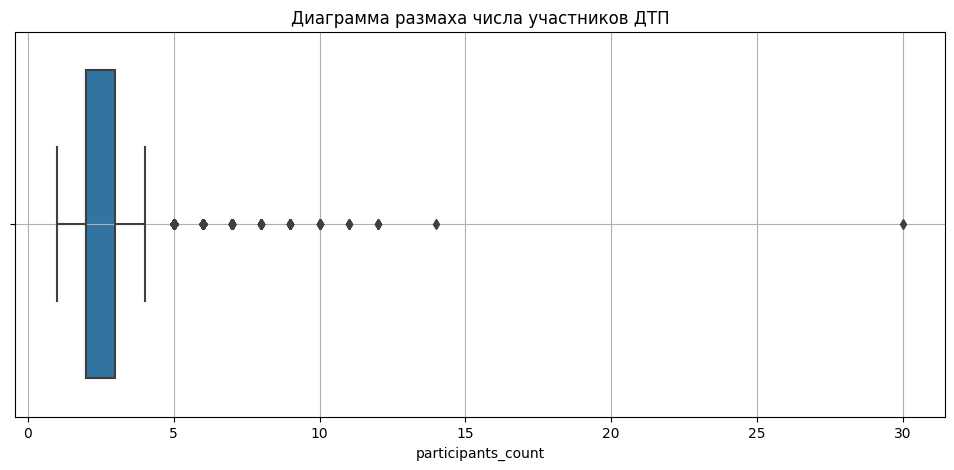

In [89]:
plt.figure(figsize=(12, 5))

sns.boxplot(data= df_one, x= 'participants_count')

plt.title('Диаграмма размаха числа участников ДТП')
plt.grid()
plt.show()

Действительно имеются выбросы значений, которые могут интерпретироваться редкими случаями ДТП Значение 30 участников аномально высокое, возможно ошибка ввода данных

Посмотрим информацию по данному ДТП

In [90]:
df_one[df_one['participants_count']==30]

,geometry_coordinates,id,tags,light,point_lat,point_long,nearby,region,scheme,address,...,injured_count,parent_region,road_conditions,participants_count,participant_categories,role,gender,violations,health_status,years_of_driving_experience
11345,"[49.611833, 58.585626]",2822118,Дорожно-транспортные происшествия,Светлое время суток,58.585626,49.611833,"['Выезд с прилегающей территории', 'Крупный то...",Киров,930.0,"г Киров, ул Производственная, 24В",...,30,Кировская область,"['Сухое', 'Отсутствие, плохая различимость гор...",30,['Все участники'],Водитель,Мужской,['Нарушение правил проезда пешеходного переход...,Не пострадал,7.0


Число пострадавших и число участников ДТП одинаковое, не похоже на ошибку ввода данных. Поиск в интернете показал, что такое ДТП действительно случилось с пассажирским автобусом в Кировской области по этому адресу.

Не будем учитывать это значение чтобы определить наиболее типичное значение числа участников ДТП

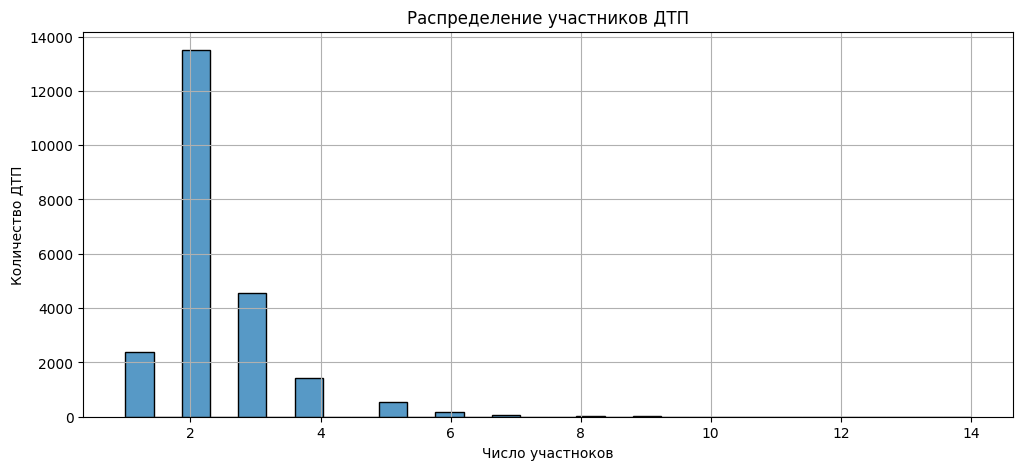

In [91]:
plt.figure(figsize=(12, 5))

sns.histplot(data= df_one[df_one['participants_count'] < 30], x= 'participants_count', bins= 30)

plt.title('Распределение участников ДТП')
plt.ylabel('Количество ДТП')
plt.xlabel('Число участноков')

plt.grid()
plt.show()

Наиболее типичное число участников ДТП 2.

In [92]:
df_participants = pd.DataFrame({'Число ДТП': df_one.groupby('participants_count')['id'].nunique(),
                             'Процент': round(df_one.groupby('participants_count')['id'].nunique() / df_one.groupby('participants_count')['id'].nunique().sum(), 4)*100
                            }).head(15)

df_participants_sorted = df_participants.sort_values(by='Число ДТП', ascending=False).reset_index()
df_participants_sorted = df_participants_sorted.rename(columns={'participants_count':'Число участников'})
df_participants_sorted['№'] = range(1, len(df_participants_sorted) + 1)
df_participants_sorted = df_participants_sorted.set_index('№')
df_participants_sorted = df_participants_sorted.style.background_gradient(cmap='coolwarm')
df_participants_sorted

,Число участников,Число ДТП,Процент
№,,,
1,2,8611,59.320000
2,3,2929,20.180000
3,1,1533,10.560000
4,4,909,6.260000
5,5,353,2.430000
6,6,109,0.750000
7,7,44,0.300000
8,8,9,0.060000
9,9,9,0.060000


- 59,3 % случаев ДТП происходит с 2 участниками, это вполне логично, учитывая, что как правило в ДТП учавствуют 2 стороны: водитель-водитель или водитель-пешеход.
- 20,2 % с 3 участниками, по-видимому с участием еще и пассажира
- 10,6 с одним в случаях ДТП с одним ТС, например при сьезде с дороги

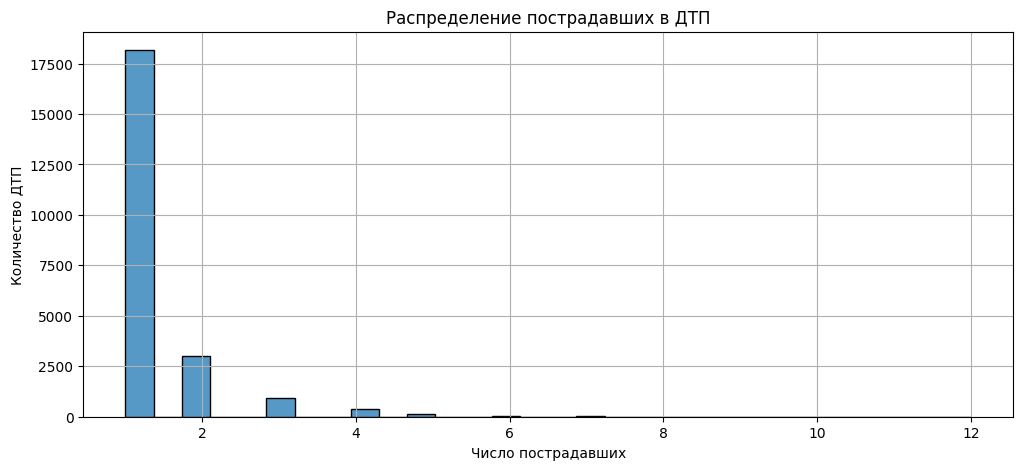

In [93]:
plt.figure(figsize=(12, 5))

sns.histplot(data=df_one[df_one['injured_count'] < 30], x= 'injured_count', bins=30)

plt.title('Распределение пострадавших в ДТП')
plt.ylabel('Количество ДТП')
plt.xlabel('Число пострадавших')

plt.grid()
plt.show()

In [94]:
df_injured = pd.DataFrame({'Число ДТП': df_one.groupby('injured_count')['id'].nunique(),
                             'Процент': round(df_one.groupby('injured_count')['id'].nunique() / df_one.groupby('injured_count')['id'].nunique().sum(), 4)*100
                            }).head(15)

df_injured_sorted = df_injured.sort_values(by='Число ДТП', ascending=False).reset_index()
df_injured_sorted = df_injured_sorted.rename(columns={'injured_count':'Число пострадавших'})
df_injured_sorted['№'] = range(1, len(df_injured_sorted) + 1)
df_injured_sorted = df_injured_sorted.set_index('№')
df_injured_sorted=df_injured_sorted.style.background_gradient(cmap='coolwarm')
df_injured_sorted

,Число пострадавших,Число ДТП,Процент
№,,,
1,1,11562,79.640000
2,2,1959,13.490000
3,3,616,4.240000
4,4,243,1.670000
5,5,86,0.590000
6,6,29,0.200000
7,7,12,0.080000
8,8,4,0.030000
9,9,2,0.010000


В 79,6 % случаев ДТП имеется один пострадавший, двое в 13,5 % происшествий, трое в 4,2 %

2. Предположение и проверка корреляции между столбцами

Для этого применим рассчет коэффициента корреляции phi k

interval columns not set, guessing: ['years_of_driving_experience', 'injured_count']


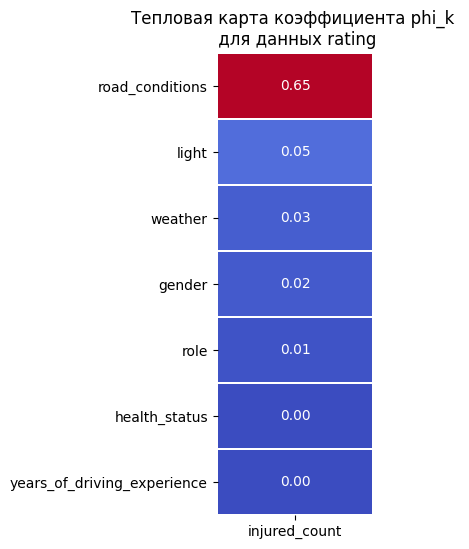

In [95]:
correlation_matrix = df_one[['light', 'weather', 'road_conditions', 'gender', 'health_status',
                         'years_of_driving_experience', 'role', 'injured_count']].phik_matrix()

plt.figure(figsize=(2, 6))

data_heatmap = correlation_matrix.loc[correlation_matrix.index != 'injured_count'][['injured_count']].sort_values(by='injured_count', ascending=False)
sns.heatmap(data_heatmap,
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm', 
            linewidths=0.5, 
            cbar=False 
           )
plt.title('Тепловая карта коэффициента phi_k \n для данных rating')
plt.show()

Очевидна сильная корреляция между пострадавшими и дорожным покрытием. Следует глубже исследовать эту взаимосвязь

In [96]:
df_exploded = df_one.copy()
df_exploded["road_conditions"] = df_exploded["road_conditions"].apply(ast.literal_eval)
df_exploded = df_exploded.explode("road_conditions")

Выведем число ДТП в зависимости от состояния дорожного покрытия

In [97]:
df_exp = df_exploded.groupby('road_conditions')['id'].nunique().sort_values(ascending = False).reset_index().head(10)
df_exp['mean']=df_exp['id']/df_exp['id'].sum()
df_exp.style.background_gradient(cmap='coolwarm')

,road_conditions,id,mean
0,Сухое,8019,0.342883
1,"Отсутствие, плохая различимость горизонтальной разметки проезжей части",5027,0.214948
2,Мокрое,2949,0.126096
3,Обработанное противогололедными материалами,1701,0.072733
4,Отсутствие дорожных знаков в необходимых местах,1658,0.070894
5,Заснеженное,1241,0.053064
6,Недостатки зимнего содержания,819,0.035019
7,Отсутствие пешеходных ограждений в необходимых местах,680,0.029076
8,Отсутствие тротуаров (пешеходных дорожек),663,0.028349
9,"Неправильное применение, плохая видимость дорожных знаков",630,0.026938


Выясним как суммарное число пострадавших зависит от состояния дорожного покрытия зависит

In [98]:
df_injured = df_exploded.groupby(['road_conditions', 'injured_count'])['id'].nunique().reset_index().sort_values(by=[ 'id'], ascending=False)
df_injured_sum = df_injured.groupby('road_conditions')['injured_count'].sum().sort_values( ascending=False)
df_injured_sum.reset_index().head(10).style.background_gradient(cmap='coolwarm')

,road_conditions,injured_count
0,"Отсутствие, плохая различимость горизонтальной разметки проезжей части",88
1,Сухое,78
2,Заснеженное,55
3,Недостатки зимнего содержания,55
4,Мокрое,45
5,Отсутствие элементов обустройства остановочного пункта общественного пассажирского транспорта,41
6,Со снежным накатом,38
7,Отсутствие дорожных знаков в необходимых местах,33
8,Обработанное противогололедными материалами,29
9,Отсутствие тротуаров (пешеходных дорожек),28


Отобразим на линейчатой диаграмме

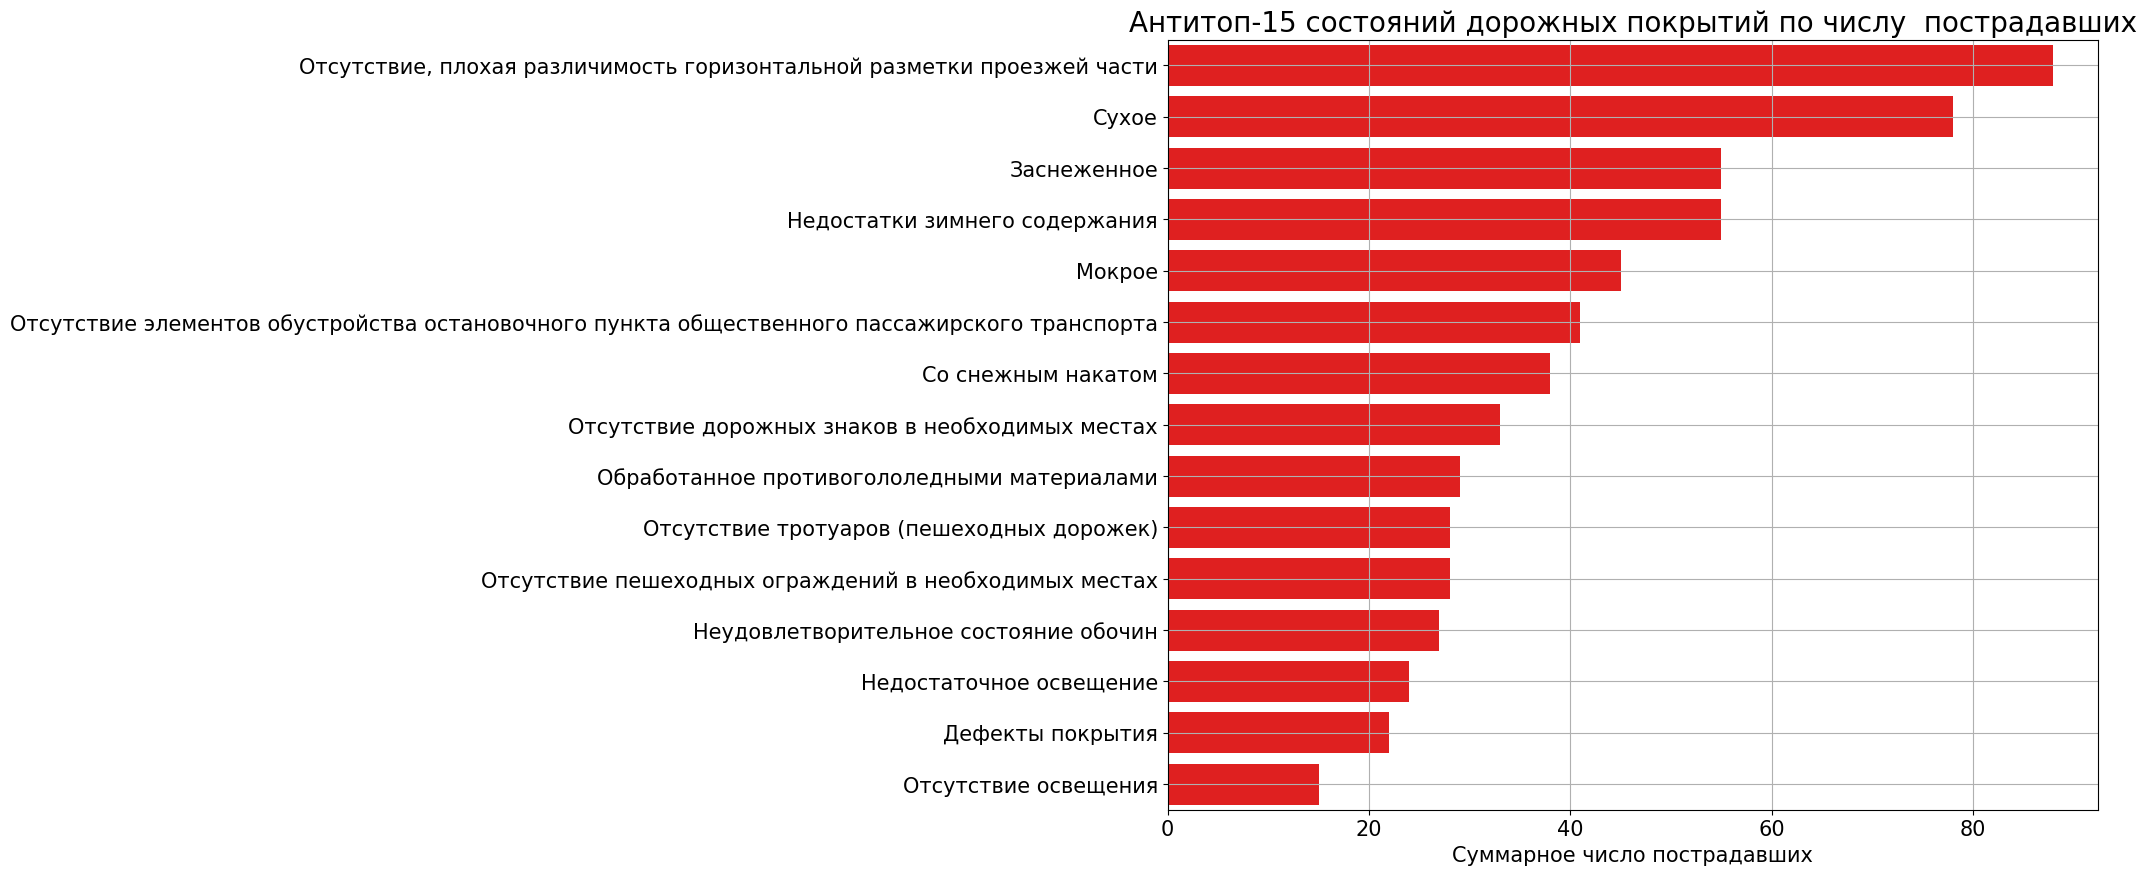

In [99]:
df_injured_sum=df_injured_sum.reset_index().head(15)

# Построение диаграммы
plt.figure(figsize=(12, 10))

ax=sns.barplot(x= 'injured_count', y='road_conditions', data=df_injured_sum, color='red')

plt.title('Антитоп-15 состояний дорожных покрытий по числу  пострадавших', fontsize=20)
plt.xlabel('Суммарное число пострадавших', fontsize=15)
plt.ylabel(None)
plt.yticks(fontsize=15)
plt.xticks(fontsize=15)
plt.grid()
plt.show()

Чаще всего на число пострадавших в ДТП влияет отсутствие, плохая различимость горизонтальной разметки проезжей части

3. Связь категории аварий с погодными условиями

In [100]:
df_group_cat_wet = df_one.groupby(['category', 'weather'])['id'].nunique().sort_values(ascending=False).head(20).reset_index()

df_group_cat_wet

,category,weather,id
0,Столкновение,['Пасмурно'],2514
1,Столкновение,['Ясно'],2288
2,Наезд на пешехода,['Пасмурно'],2268
3,Наезд на пешехода,['Ясно'],1572
4,Съезд с дороги,['Ясно'],586
5,Опрокидывание,['Ясно'],532
6,Съезд с дороги,['Пасмурно'],431
7,Наезд на велосипедиста,['Ясно'],397
8,Падение пассажира,['Пасмурно'],390
9,Опрокидывание,['Пасмурно'],367


Выведем число случаев ДТП по категория ДТП

In [101]:
category= pd.DataFrame(df_one['category'].value_counts()).reset_index()

category

,index,category
0,Столкновение,8524
1,Наезд на пешехода,6831
2,Съезд с дороги,1798
3,Опрокидывание,1516
4,Падение пассажира,1158
5,Наезд на препятствие,1019
6,Наезд на велосипедиста,910
7,Наезд на стоящее ТС,497
8,Иной вид ДТП,207
9,Наезд на животное,146


Число ДТП по погодным условиям

In [102]:
weather= pd.DataFrame(df_one['weather'].value_counts()).reset_index().style.background_gradient(cmap='coolwarm')

weather

,index,weather
0,['Пасмурно'],10464
1,['Ясно'],9802
2,['Снегопад'],981
3,['Дождь'],930
4,"['Пасмурно', 'Снегопад']",153
5,"['Пасмурно', 'Дождь']",119
6,"['Ясно', 'Температура выше +30С']",100
7,['Метель'],43
8,['Туман'],28
9,"['Снегопад', 'Метель']",19


Построим тепловую карту числа ДТП по категориям ДТП от погодных условий

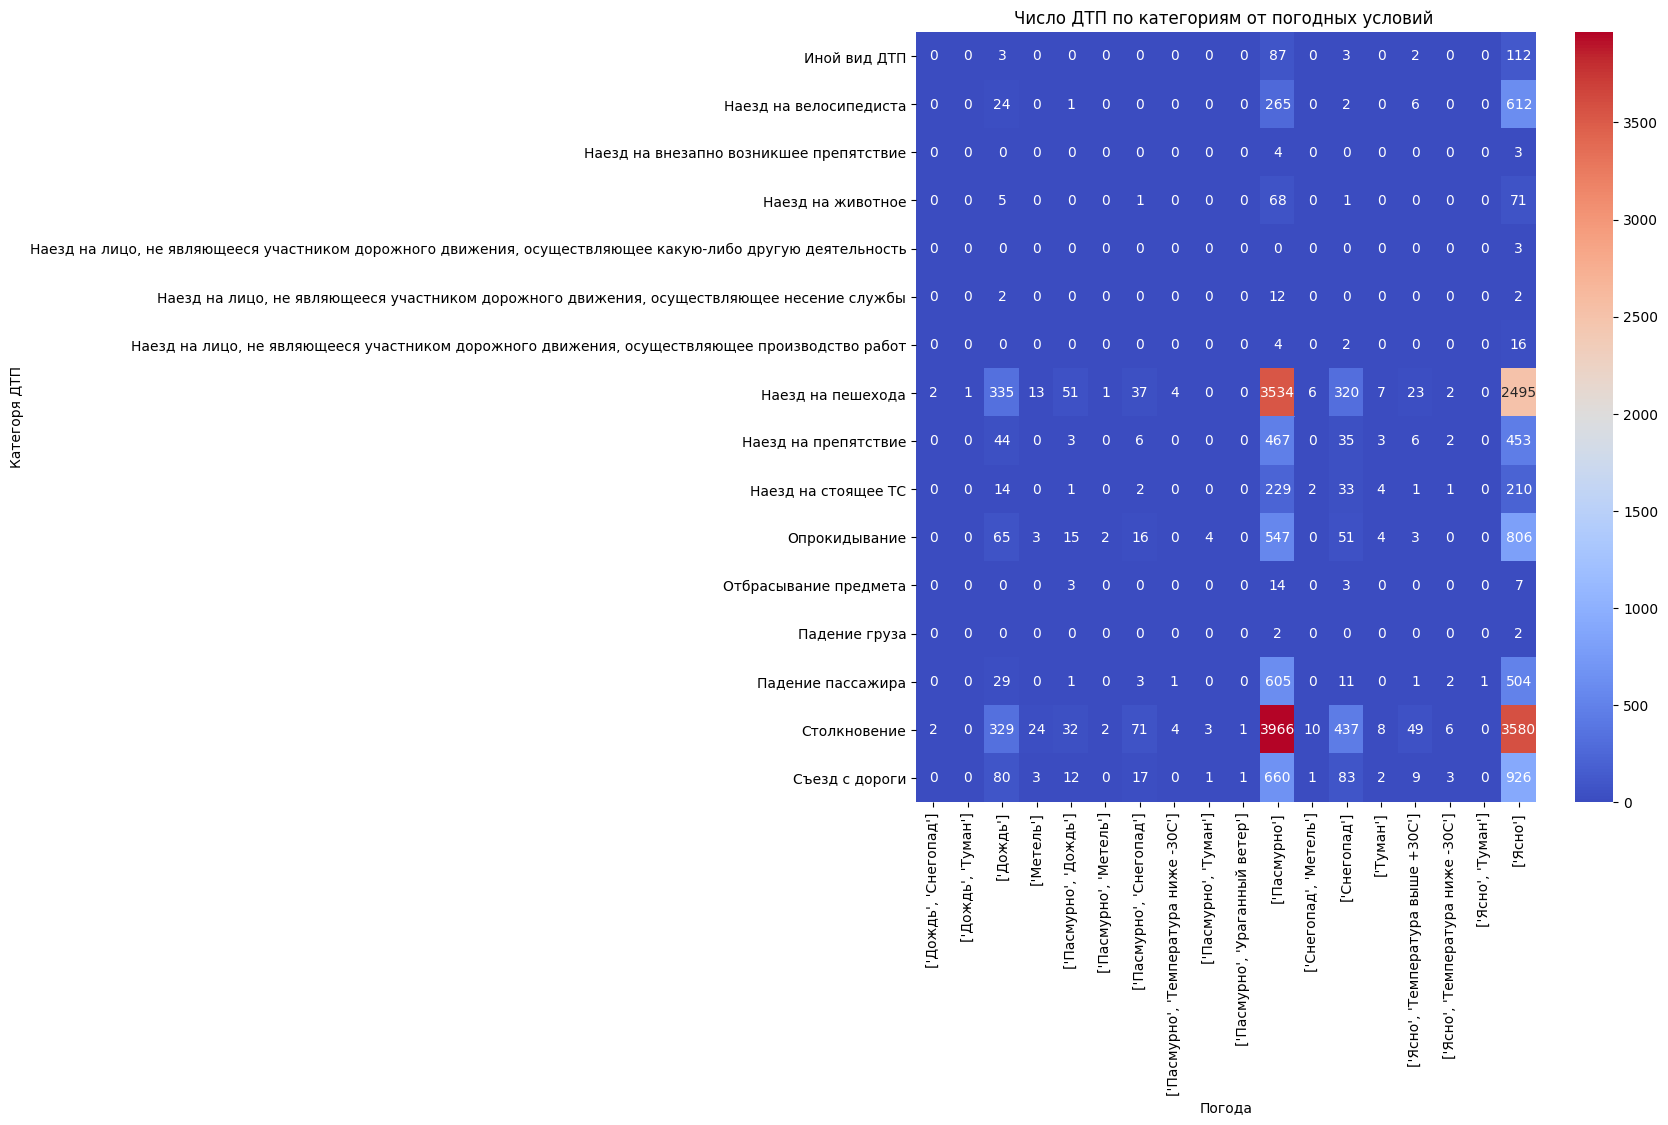

In [103]:
cross_table = pd.crosstab(df_one['category'], df_one['weather'])

# Тепловая карта
plt.figure(figsize=(10, 10))
sns.heatmap(
    cross_table, 
    annot=True,   
    cmap='coolwarm', 
    fmt='d',
)
plt.title('Число ДТП по категориям от погодных условий ')
plt.xlabel('Погода')
plt.ylabel('Категоря ДТП')
plt.show()

- Самые частые категории ДТП столкновение, наезд на пешехода и съезд с дороги
- Самые частые погодные условия пасмурно, ясно, снегопад, дождь

4. Процентная разбивка аварий по видам освещённости с учетом пола участника и сделаем расчёты для мужчин и женщин отдельно.

In [104]:
mans_light = round(df_one[df_one['gender']=='Мужской'].groupby('light')['gender'].count() /
      ((df_one['gender']=='Мужской').sum()), 3)*100
mans_light

light
В темное время суток, освещение включено       21.8
В темное время суток, освещение не включено     1.5
В темное время суток, освещение отсутствует     9.8
Светлое время суток                            63.8
Сумерки                                         3.1
Name: gender, dtype: float64

In [105]:
womans_light = round(df_one[df_one['gender']=='Женский'].groupby('light')['gender'].count()/
      ((df_one['gender']=='Женский').sum()), 3)*100
womans_light

light
В темное время суток, освещение включено       22.4
В темное время суток, освещение не включено     1.3
В темное время суток, освещение отсутствует     9.2
Светлое время суток                            64.4
Сумерки                                         2.7
Name: gender, dtype: float64

In [106]:
mans_womans_light = pd.DataFrame({'Мужчины': mans_light,
                                  'Женщины': womans_light
    
})
mans_womans_light

,Мужчины,Женщины
light,,
"В темное время суток, освещение включено",21.8,22.4
"В темное время суток, освещение не включено",1.5,1.3
"В темное время суток, освещение отсутствует",9.8,9.2
Светлое время суток,63.8,64.4
Сумерки,3.1,2.7


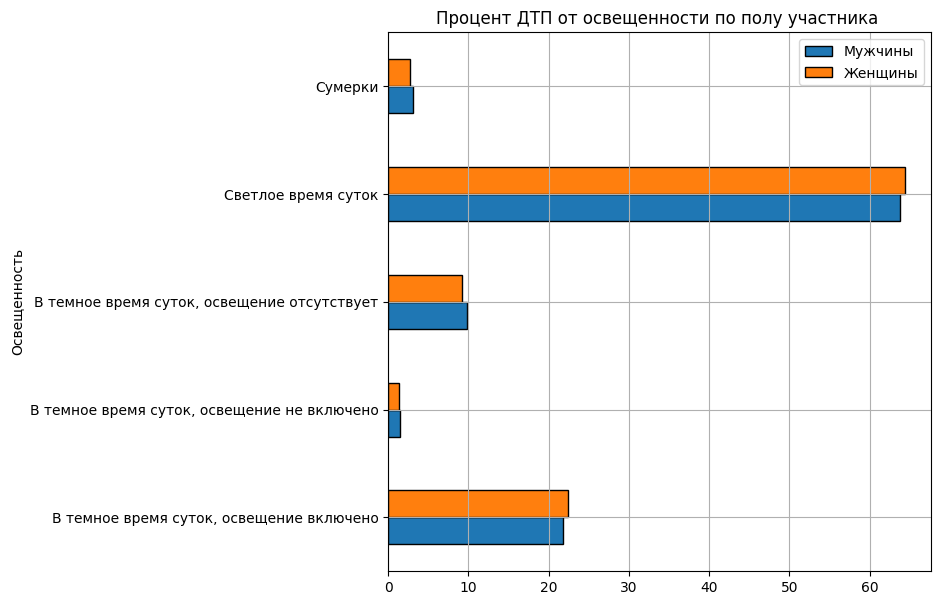

In [107]:
mans_womans_light.plot(kind='barh',
               title='Процент ДТП от освещенности по полу участника ',
               legend=True,
               xlabel='Освещенность',
               ylabel='Процент, %',
               rot=0,
               edgecolor = 'black',
               figsize=(7, 7))
plt.grid()
plt.show()

- Для мужчин и женщин в целом характерны приблизительно равные доли участия в ДТП.
- Участия женщин больше, чем мужчин в светлое время суток (64.4% и 63.8% соответственно) и темное с включенным освещением (22.4% и 21.8% соответственно)
- Участия мужчин больше чем женщин в сумерках (3.1% и 2.7% соответственно), в темное время суток, освещение не включено (1.5% и 1.3% соответственно) и в в темное время суток, освещение отсутствует (9.8% и 9.2% соответственно)
- В затемненных условиях участие в ДТП мужчин больше, а в условиях с освещением больше участие женщин

5. Исследование отличия аварий без пострадавших от тех, в которых был один пострадавший или более.

In [108]:
import numpy as np

In [109]:
df_one['binary'] = np.where(df_one['health_status'] == 'не пострадал', 0, 1)

Для того чтобы определить условия, которые влияют на значения в бинарном столбце построим матрицу корреляции других признаков с этим столбцом

In [110]:
df_one.groupby('violations')['binary'].sum().sort_values(ascending=False).head()

violations
[]                                                          9209
['Несоблюдение очередности проезда']                         979
['Другие нарушения ПДД водителем']                           765
['Несоответствие скорости конкретным условиям движения']     665
['Нарушение правил проезда пешеходного перехода']            607
Name: binary, dtype: int32

Сильная корреляция со столбцом violations, по видимому обусловлена тем, что для ДТП с пострадавшими конкретное правило, которое было нарушено не указано

Для оценки различия ДТП с пострадавшими и без будем использовать показатель доли пострадавших в зависимости от признака

In [111]:
df_one.groupby('role')['binary'].agg(['mean', 'count']).sort_values(by = 'mean', ascending=False).style.background_gradient(cmap='coolwarm')

,mean,count
role,,
Велосипедист,1,222
Водитель,1,13025
Пассажир,1,3961
Пешеход,1,4236
"Пешеход, перед ДТП находившийся в (на) ТС в качестве водителя или пешеход, перед ДТП находившийся в (на) ТС в качестве пассажира",1,64


In [112]:
df_one.groupby('gender')['binary'].agg(['mean', 'count']).sort_values(by = 'mean', ascending=False).style.background_gradient(cmap='coolwarm')

,mean,count
gender,,
Женский,1,6538
Мужской,1,14413
нет данных,1,557


In [113]:
df_one.groupby('gender')['binary'].agg(['mean', 'count']).sort_values(by = 'mean', ascending=False).style.background_gradient(cmap='coolwarm')

,mean,count
gender,,
Женский,1,6538
Мужской,1,14413
нет данных,1,557


In [114]:
df_one.groupby('region')['binary'].agg(['mean', 'count']).sort_values(by = 'mean', ascending=False).head(10).style.background_gradient(cmap='coolwarm')

,mean,count
region,,
Арбажский район,1,113
Афанасьевский район,1,213
Омутнинский район,1,539
Опаринскийрайон,1,41
Оричевский район,1,580
Орловский район,1,268
Пижанский район,1,132
Подосиновский район,1,146
Санчурский район,1,74


- Наиболее типичное число участников ДТП 2.
- 59,3 % случаев ДТП происходит с 2 участниками, это вполне логично, учитывая, что как правило в ДТП учавствуют 2 стороны: водитель-водитель или водитель-пешеход, 20,2 % с 3 участниками, по-видимому с участием еще и пассажира, 10,6 с одним в случаях ДТП с одним ТС, например при сьезде с дороги.
- В 79,6 % случаев ДТП имеется один пострадавший, двое в 13,5 % происшествий, трое в 4,2 %
- Чаще всего на число пострадавших в ДТП влияет отсутствие, плохая различимость горизонтальной разметки проезжей части
- Самые частые категории ДТП столкновение, наезд на пешехода и съезд с дороги
- Самые опасные погодные условия пасмурно, ясно, снегопад, дождь
- Для мужчин и женщин в целом характерны приблизительно равные доли участия в ДТП.
- Участия женщин больше, чем мужчин в светлое время суток (64.4% и 63.8% соответственно) и темное с включенным освещением (22.4% и 21.8% соответственно)
- Участия мужчин больше чем женщин в сумерках (3.1% и 2.7% соответственно), в темное время суток, освещение не включено (1.5% и 1.3% соответственно) и в в темное время суток, освещение отсутствует (9.8% и 9.2% соответственно)
- В затемненных условиях участие в ДТП мужчин больше, а в условиях с освещением больше участие женщин

Отличие ДТП с пострадавшими коррелирует с такими признаками как нарушенное правило, роль, пол и регион Наибольшая доля пострадавших в ДТП характерна для

- участников: велосипедист (0.99), пешеход (0.99), пассажир (0.94), для водителей не характерна (0.3)
- водителей женщин (0.82) в существенно большей мере , чем для мужчин (0.46)
- регионов: Вятско-полянский район (1.0), Киропо-чепецкий район (0.87), Шабалинский район (0.74)
- топе правил нарушенных при ДТП: 'переход через проезжую часть вне пешеходного перехода', 'несоответствие скорости конкретным условиям движения'

Рекомендации
- Повысить уровень знания ПДД и безопасности для женщин
- Уделить внимание таким факторам как велосипедные дорожки, дорожная разметка и освещение дорог
- Особенно высокая аварийность с пострадавшими по Вятско-полянскому, Киропо-чепецкому и Шабалинскому районам